# Лабораторна 5. Власне донавчання: виявлення токсичних коментарів українською

**Метод:** класичне донавчання з новою головою (як у демо `01_bert_head`), модель `xlm-roberta-base`.

Для запуску в Colab: *Среда выполнения → Сменить среду выполнения → T4 GPU*, потім *Выполнить все*.

## 1.1. Задача

**Хто користувач.** Модератори коментарів українськомовного сайту, Telegram-каналу чи чату університету. Щодня з'являються сотні чи тисячі повідомлень, і переглянути всі вручну неможливо.

**Що на вході:** текст одного коментаря українською.
**Що на виході:** мітка `токсичний` / `нетоксичний` та ймовірність. Коментарі з високою ймовірністю токсичності автоматично приховуються або потрапляють у чергу на перевірку модератору.

**Чому донавчання, а не промпт чи RAG:**
- **Швидкість і вартість.** Класифікатор на 278 млн параметрів обробляє коментар за мілісекунди навіть на CPU. Генеративна LLM з промптом на кожен коментар у сотні разів повільніша й дорожча, а для потоку в тисячі повідомлень на день це суттєво.
- **Стабільний формат і поріг.** Класифікатор завжди повертає ймовірність, і поріг блокування можна налаштувати під потреби модераторів. LLM може відповісти текстом не в тому форматі, пояснювати своє рішення або відмовитися відповідати на образливий текст.
- **Мова і сленг.** Малі локальні LLM погано розуміють українську лайку, суржик і завуальовані образи. Донавчання на розмічених українських прикладах закладає саме те розуміння «токсичності», яке закладено в розмітці.
- **RAG тут не допоможе:** він додає до промпту знання з документів, а задача не потребує зовнішніх знань. Потрібно навчитися розрізняти тон тексту.

## 1.2. Модель і дані

### Модель: `FacebookAI/xlm-roberta-base`
- **Encoder-модель** (як BERT): читає весь текст одразу і добре підходить для класифікації. До неї додаємо нову голову-класифікатор на 2 класи, як у демо 1.
- **Багатомовна**, попередньо тренована на 100 мовах, зокрема на великому обсязі української (корпус CommonCrawl). `bert-base-uncased` з демо 1 знає лише англійську.
- **Розмір 278 млн параметрів** (основна частина — словник на 250 тис. токенів): повне донавчання вміщується в T4 і триває кілька хвилин.
- **Base, а не instruct:** для класифікатора з новою головою інструкції не потрібні. Ми замінюємо «голову» передбачення слів на голову класифікації.

### Дані: `textdetox/multilingual_toxicity_dataset`, частина `uk`
- **Джерело:** [Hugging Face](https://huggingface.co/datasets/textdetox/multilingual_toxicity_dataset); українські дані з роботи *Dementieva et al., «Toxicity Classification in Ukrainian», WOAH 2024*. Корпус зібрано перекладом англійського корпусу, фільтрацією за ключовими словами та розміткою краудсорсингом.
- **Ліцензія:** OpenRAIL++.
- **Розмір і формат:** 5000 прикладів, колонки `text` (рядок) і `toxic` (0 — нетоксичний, 1 — токсичний).

⚠️ Датасет містить образливі висловлювання: це необхідно для навчання моделі їх розпізнавати.

In [1]:
!pip install -q "transformers>=4.46" datasets accelerate scikit-learn

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Пристрій:", device, "|", torch.cuda.get_device_name() if device == "cuda" else "увімкніть GPU T4")

Пристрій: cuda | Tesla T4


In [3]:
raw = load_dataset("textdetox/multilingual_toxicity_dataset", split="uk")
print(raw)

df = raw.to_pandas()
print("\nРозподіл класів:")
print(df["toxic"].value_counts().rename({0: "нетоксичний (0)", 1: "токсичний (1)"}))
print("\nДовжина тексту, символів:")
print(df["text"].str.len().describe().round(1))

README.md:   0%|          | 0.00/8.91k [00:00<?, ?B/s]

data/en-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  267kB            

data/en-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/ru-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  388kB            

data/ru-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/uk-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  360kB            

... (37 outputs left out)

Generating hin split:   0%|          | 0/4363 [00:00<?, ? examples/s]

Generating tt split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating ja split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'toxic'],
    num_rows: 5000
})

Розподіл класів:
toxic
нетоксичний (0)    2500
токсичний (1)      2500
Name: count, dtype: int64

Довжина тексту, символів:
count    5000.0
mean       63.7
std        59.5
min         7.0
25%        42.0
50%        56.0
75%        79.0
max      2845.0
Name: text, dtype: float64


In [4]:
# Кілька прикладів кожного класу
pd.set_option("display.max_colwidth", 150)
display(pd.concat([
    df[df["toxic"] == 0].sample(4, random_state=1),
    df[df["toxic"] == 1].sample(4, random_state=1),
]))

,text,toxic
1406,Ердоган схоже знову ворог Numéro Uno.,0
297,Всі оголошення в Хюндаї робляться українською і англійською мовами.,0
1276,"Мда, як же любить народ щось густеньке біле.",0
2368,Тіпа капєц кидай всьо бягі мене развлєкать.,0
3906,"о,цікаво,прадід і цього разу кричатиме після виборів,що ""до влади прийшли одні жиди""? утім,про вфя було ""гірше жида,кацапура такий-сякий"".",1
2797,"Каюсь, в 11 хотіла того ж, але курва, ну зачем?",1
3776,там така жопа в деяких фотках що блять пздц,1
4868,"Ой, кожна школа єбанута по-своєму) це вже третя моя, я знаю, що кажу))",1


### Поділ на train / validation / test

Спершу прибираємо дублікати текстів, щоб один і той самий коментар не потрапив і в тренування, і в тест: інакше оцінка була б завищеною.
Потім ділимо **зі стратифікацією** (однакова частка токсичних у кожному наборі) у пропорції 80 / 10 / 10.
Тестовий набір використовуємо лише для підсумкової оцінки: ні під час тренування, ні для вибору гіперпараметрів.

In [5]:
from sklearn.model_selection import train_test_split

df["key"] = df["text"].str.strip().str.lower()
before = len(df)
df = df.drop_duplicates("key").drop(columns="key").reset_index(drop=True)
print(f"До дедуплікації: {before}, після: {len(df)}")

train_df, rest_df = train_test_split(df, test_size=0.2, stratify=df["toxic"], random_state=42)
val_df, test_df = train_test_split(rest_df, test_size=0.5, stratify=rest_df["toxic"], random_state=42)

# Перевірка: жоден тестовий текст не потрапив у тренування
assert not set(test_df["text"]) & set(train_df["text"])

for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:<11} {len(part):5d} прикладів, токсичних {part['toxic'].mean():.1%}")

До дедуплікації: 5000, після: 4997
train        3997 прикладів, токсичних 50.0%
validation    500 прикладів, токсичних 50.0%
test          500 прикладів, токсичних 50.0%


## 1.3. Модель до донавчання

### Метрика
- **F1 для класу «токсичний»** — головна метрика. Вона враховує і пропущені токсичні коментарі (recall), і помилково заблоковані нормальні (precision). Для модерації важливі обидва типи помилок, а accuracy може бути високою навіть у моделі, яка погано знаходить токсичні коментарі.
- **Accuracy** — загальна частка правильних відповідей, для наочності.
- **Macro-F1** — середнє F1 обох класів, щоб модель не «жертвувала» одним із них.

### Базові рівні
1. **«Завжди найчастіший клас»** — найпростіший класифікатор, з яким треба порівнювати.
2. **`xlm-roberta-base` з новою, ще не натренованою головою** — показує, що сама по собі попередньо тренована модель не вміє цієї задачі: голова ініціалізована випадково.

In [6]:
def metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1 (токсичний)": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Macro-F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

results = {}

# Базовий рівень 1: завжди найчастіший клас тренувального набору
majority = int(train_df["toxic"].mode()[0])
print("Найчастіший клас у train:", majority)
results["Завжди найчастіший клас"] = metrics(test_df["toxic"], [majority] * len(test_df))
pd.DataFrame(results).T.round(3)

Найчастіший клас у train: 0


,Accuracy,F1 (токсичний),Macro-F1
Завжди найчастіший клас,0.5,0.0,0.333


In [7]:
from datasets import Dataset

checkpoint = "FacebookAI/xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

def to_ds(part):
    return Dataset.from_pandas(part.rename(columns={"toxic": "label"})[["text", "label"]], preserve_index=False)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

datasets = {name: to_ds(part).map(tokenize, batched=True) for name, part in
            [("train", train_df), ("validation", val_df), ("test", test_df)]}
collator = DataCollatorWithPadding(tokenizer)

lengths = [len(x) for x in datasets["train"]["input_ids"]]
print(f"Довжина в токенах: медіана {int(np.median(lengths))}, 95-й перцентиль {int(np.percentile(lengths, 95))}, "
      f"обрізано (>128): {np.mean(np.array(lengths) >= 128):.1%}")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/3997 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Довжина в токенах: медіана 21, 95-й перцентиль 39, обрізано (>128): 0.1%


In [8]:
model = AutoModelForSequenceClassification.from_pretrained(
    checkpoint, num_labels=2,
    id2label={0: "нетоксичний", 1: "токсичний"}, label2id={"нетоксичний": 0, "токсичний": 1},
)
print(model.classifier)
n_total = sum(p.numel() for p in model.parameters())
n_head = sum(p.numel() for p in model.classifier.parameters())
print(f"Усього параметрів: {n_total:,}; у голові: {n_head:,} ({n_head / n_total:.2%})")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


XLMRobertaClassificationHead(
  (dense): Linear(in_features=768, out_features=768, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (out_proj): Linear(in_features=768, out_features=2, bias=True)
)
Усього параметрів: 278,045,186; у голові: 592,130 (0.21%)


In [10]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return metrics(labels, np.argmax(logits, axis=-1))


def predict_labels(trainer, ds):
    out = trainer.predict(ds)
    probs = torch.tensor(out.predictions).softmax(-1)[:, 1].numpy()
    return np.argmax(out.predictions, axis=-1), probs


args = TrainingArguments(
    output_dir="xlmr-uk-toxicity",
    num_train_epochs=4,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    warmup_steps=100,
    eval_strategy="epoch",
    logging_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,      # наприкінці беремо епоху з найкращим F1 на валідації
    metric_for_best_model="F1 (токсичний)",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=datasets["train"], eval_dataset=datasets["validation"],
    data_collator=collator, processing_class=tokenizer, compute_metrics=compute_metrics,
)

# Базовий рівень 2: модель з новою, ще не натренованою головою
pred_before, prob_before = predict_labels(trainer, datasets["test"])
results["xlm-roberta-base до донавчання"] = metrics(test_df["toxic"], pred_before)
pd.DataFrame(results).T.round(3)

,Accuracy,F1 (токсичний),Macro-F1
Завжди найчастіший клас,0.5,0.0,0.333
xlm-roberta-base до донавчання,0.5,0.0,0.333


### Приклади відповідей моделі до донавчання

Беремо 10 тестових прикладів (5 токсичних і 5 нетоксичних) і показуємо їх і до, і після донавчання.

In [11]:
LABEL = {0: "нетоксичний", 1: "токсичний"}
test_reset = test_df.reset_index(drop=True)
sample_idx = list(test_reset[test_reset["toxic"] == 1].sample(5, random_state=7).index) + \
             list(test_reset[test_reset["toxic"] == 0].sample(5, random_state=7).index)

pd.DataFrame({
    "текст": test_reset.loc[sample_idx, "text"].str.slice(0, 120),
    "правильно": test_reset.loc[sample_idx, "toxic"].map(LABEL),
    "до донавчання": [LABEL[int(pred_before[i])] for i in sample_idx],
    "P(токсичний) до": prob_before[sample_idx].round(2),
})

,текст,правильно,до донавчання,P(токсичний) до
316,Лещєнко & рахунки з ресторану Лещєнко & ліпецькі ґвалтівники журналістів Лещєнко & охуїтєльні історії,токсичний,нетоксичний,0.42
450,хахаха я єбав знову таке малювати,токсичний,нетоксичний,0.41
192,"Саакашвілі заявив, що не претендує на державні посади Саакашвілі готовий очолити уряд Саакашвілі іде нахуй.",токсичний,нетоксичний,0.41
174,"Я теж мав сподівання, щодо Саакашвілі – але це ж пиздець.",токсичний,нетоксичний,0.41
5,"Я звичайно не надто музику у вк слухав, але бляха, як я тепер без класних аудіо ?",токсичний,нетоксичний,0.41
287,.. при чому людей які обробляють дорогоцінне каміння не так багато.,нетоксичний,нетоксичний,0.42
425,"Ти мій син, але другого я люблю більше",нетоксичний,нетоксичний,0.42
185,Трамп зацарює і Путін відповідно нападе.,нетоксичний,нетоксичний,0.41
160,"Мужик, в тебе півтора к підпісників в інстаграмі, як ти, бляха, моментально помітив, що я відписалася?????",нетоксичний,нетоксичний,0.42
9,Нарізав вам фрагменти вчорашнього ефіру з Мураєвим.,нетоксичний,нетоксичний,0.41


## 1.4. Донавчання

**Метод:** повне донавчання з новою головою (оновлюються всі ваги, кістяк і голова), як у демо 1.
LoRA тут не потрібна: модель невелика (278 млн параметрів) і повністю вміщується в T4.

**Гіперпараметри:**
| Параметр | Значення | Чому |
|---|---|---|
| learning rate | 2e-5 | Стандарт для повного донавчання BERT-подібних моделей: малий крок не руйнує знання з попереднього тренування |
| епохи | 4 | 4000 прикладів — невеликий датасет, 2–4 епохи зазвичай достатньо. Перенавчання контролюємо по validation loss, а `load_best_model_at_end` бере найкращу епоху |
| розмір батча | 16 | Вміщується в пам'ять T4 з запасом, стандарт для BERT-подібних моделей |
| max_length | 128 токенів | Коментарі короткі: 95% коротші за цю межу (див. вище) |
| warmup 10%, weight decay 0.01 | — | Плавний старт навчання і легка регуляризація: стандартні налаштування |
| fp16 | так | Змішана точність пришвидшує тренування на T4 |

In [12]:
torch.cuda.reset_peak_memory_stats() if device == "cuda" else None
start = time.time()
trainer.train()
train_minutes = (time.time() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float("nan")
print(f"\nТривалість тренування: {train_minutes:.1f} хв, пікова пам'ять GPU: {peak_gb:.2f} GB")

Epoch,Training Loss,Validation Loss,Accuracy,F1 (токсичний),Macro-f1
1,0.540644,0.310708,0.878000,0.875256,0.877941
2,0.277510,0.258737,0.890000,0.893617,0.889873
3,0.192274,0.452612,0.902000,0.901804,0.902000
4,0.151492,0.439896,0.908000,0.909449,0.907976


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Тривалість тренування: 7.3 хв, пікова пам'ять GPU: 4.50 GB


,Епоха,Training loss,Validation loss,Val accuracy,Val F1 (токсичний)
0,1.0,0.5406,0.3107,0.878,0.8753
1,2.0,0.2775,0.2587,0.890,0.8936
2,3.0,0.1923,0.4526,0.902,0.9018
3,4.0,0.1515,0.4399,0.908,0.9094


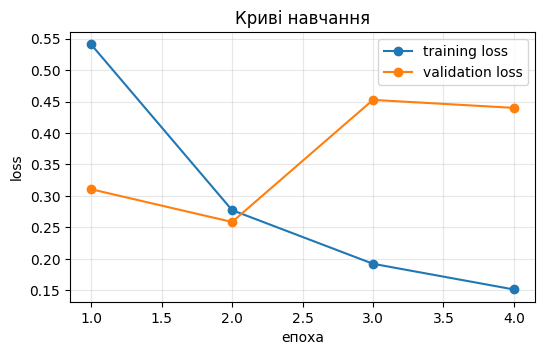

Найкраща епоха (за F1 на валідації): xlmr-uk-toxicity/checkpoint-1000


In [13]:
# Таблиця і графік training / validation loss по епохах
log = pd.DataFrame(trainer.state.log_history)
train_loss = log.dropna(subset=["loss"])[["epoch", "loss"]]
eval_log = log.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_Accuracy", "eval_F1 (токсичний)"]]
history = train_loss.merge(eval_log, on="epoch").round(4)
history.columns = ["Епоха", "Training loss", "Validation loss", "Val accuracy", "Val F1 (токсичний)"]
display(history)

plt.figure(figsize=(6, 3.5))
plt.plot(history["Епоха"], history["Training loss"], marker="o", label="training loss")
plt.plot(history["Епоха"], history["Validation loss"], marker="o", label="validation loss")
plt.xlabel("епоха"); plt.ylabel("loss"); plt.title("Криві навчання"); plt.grid(alpha=0.3); plt.legend()
plt.show()
print("Найкраща епоха (за F1 на валідації):", trainer.state.best_model_checkpoint)

**Результати тренування.** Тривалість **7.3 хв**, пікова пам'ять GPU **4.50 GB** (з 15 GB на T4).

| Епоха | Training loss | Validation loss | Val accuracy | Val F1 (токсичний) |
|---|---|---|---|---|
| 1 | 0.5406 | 0.3107 | 0.878 | 0.8753 |
| 2 | 0.2775 | **0.2587** | 0.890 | 0.8936 |
| 3 | 0.1923 | 0.4526 | 0.902 | 0.9018 |
| 4 | 0.1515 | 0.4399 | **0.908** | **0.9094** |

**Перенавчання.** Training loss падає на всіх епохах, а validation loss мінімальний на **2-й епосі** (0.259) і потім **зростає** (0.453 і 0.440). Це ознака початку перенавчання: модель стає надто впевненою, і на прикладах, де помиляється, помиляється з імовірністю ~99%, за що loss дає великий штраф (так само було в демо 1, питання 9). Водночас accuracy і F1 на валідації **продовжують зростати** до 4-ї епохи (F1 0.894 → 0.909), тобто кількість правильних відповідей усе ще збільшується.

**Що з цим зроблено:** параметр `load_best_model_at_end=True` з `metric_for_best_model="F1 (токсичний)"` наприкінці бере епоху з найкращим F1 на валідації. Це 4-та епоха (`checkpoint-1000`). Я обрала F1, а не validation loss, бо для модерації важлива саме кількість правильних рішень, а не впевненість моделі. Якби збільшити кількість епох далі, F1 почав би падати, тому 4 епохи — розумна межа. Альтернатива — зупинитися на 2-й епосі за мінімальним validation loss (F1 0.894, лише на 1.6 пункти гірше).

## 1.5. Порівняння до і після донавчання

In [14]:
pred_after, prob_after = predict_labels(trainer, datasets["test"])
results["xlm-roberta-base після донавчання"] = metrics(test_df["toxic"], pred_after)
comparison = pd.DataFrame(results).T.round(3)
display(comparison)

print(classification_report(test_df["toxic"], pred_after, target_names=["нетоксичний", "токсичний"], digits=3))
cm = confusion_matrix(test_df["toxic"], pred_after)
display(pd.DataFrame(cm, index=["справді нетоксичний", "справді токсичний"],
                     columns=["передбачено нетоксичний", "передбачено токсичний"]))

,Accuracy,F1 (токсичний),Macro-F1
Завжди найчастіший клас,0.500,0.000,0.333
xlm-roberta-base до донавчання,0.500,0.000,0.333
xlm-roberta-base після донавчання,0.892,0.892,0.892


              precision    recall  f1-score   support

 нетоксичний      0.892     0.892     0.892       250
   токсичний      0.892     0.892     0.892       250

    accuracy                          0.892       500
   macro avg      0.892     0.892     0.892       500
weighted avg      0.892     0.892     0.892       500



,передбачено нетоксичний,передбачено токсичний
справді нетоксичний,223,27
справді токсичний,27,223


In [15]:
# Ті самі 10 тестових прикладів до і після донавчання
pd.DataFrame({
    "текст": test_reset.loc[sample_idx, "text"].str.slice(0, 120),
    "правильно": test_reset.loc[sample_idx, "toxic"].map(LABEL),
    "до": [LABEL[int(pred_before[i])] for i in sample_idx],
    "після": [LABEL[int(pred_after[i])] for i in sample_idx],
    "P(токсичний) після": prob_after[sample_idx].round(2),
})

,текст,правильно,до,після,P(токсичний) після
316,Лещєнко & рахунки з ресторану Лещєнко & ліпецькі ґвалтівники журналістів Лещєнко & охуїтєльні історії,токсичний,нетоксичний,токсичний,1.0
450,хахаха я єбав знову таке малювати,токсичний,нетоксичний,токсичний,1.0
192,"Саакашвілі заявив, що не претендує на державні посади Саакашвілі готовий очолити уряд Саакашвілі іде нахуй.",токсичний,нетоксичний,токсичний,1.0
174,"Я теж мав сподівання, щодо Саакашвілі – але це ж пиздець.",токсичний,нетоксичний,токсичний,1.0
5,"Я звичайно не надто музику у вк слухав, але бляха, як я тепер без класних аудіо ?",токсичний,нетоксичний,токсичний,1.0
287,.. при чому людей які обробляють дорогоцінне каміння не так багато.,нетоксичний,нетоксичний,нетоксичний,0.0
425,"Ти мій син, але другого я люблю більше",нетоксичний,нетоксичний,нетоксичний,0.0
185,Трамп зацарює і Путін відповідно нападе.,нетоксичний,нетоксичний,нетоксичний,0.0
160,"Мужик, в тебе півтора к підпісників в інстаграмі, як ти, бляха, моментально помітив, що я відписалася?????",нетоксичний,нетоксичний,токсичний,1.0
9,Нарізав вам фрагменти вчорашнього ефіру з Мураєвим.,нетоксичний,нетоксичний,нетоксичний,0.0


### Аналіз помилок донавченої моделі

Нижче всі помилки на тестовому наборі, окремо:
- **хибно позитивні** — нормальний коментар позначено токсичним (його б помилково приховали);
- **хибно негативні** — токсичний коментар пропущено.

Найбільш «впевнені» помилки йдуть першими.

In [16]:
errors = test_reset.assign(pred=pred_after, prob=prob_after.round(3))
fp = errors[(errors["toxic"] == 0) & (errors["pred"] == 1)].sort_values("prob", ascending=False)
fn = errors[(errors["toxic"] == 1) & (errors["pred"] == 0)].sort_values("prob")
print(f"Хибно позитивних: {len(fp)}, хибно негативних: {len(fn)}")

print("\n=== Хибно позитивні (нетоксичні, але модель вважає токсичними) ===")
display(fp[["text", "prob"]].head(10))
print("\n=== Хибно негативні (токсичні, але модель пропустила) ===")
display(fn[["text", "prob"]].head(10))

Хибно позитивних: 27, хибно негативних: 27

=== Хибно позитивні (нетоксичні, але модель вважає токсичними) ===


,text,prob
17,"Там чекають мої два жиробасіка, а не вот ета вот всьо",0.999
160,"Мужик, в тебе півтора к підпісників в інстаграмі, як ти, бляха, моментально помітив, що я відписалася?????",0.999
101,"Окей, сайт підкинув рекламу, де до мене доїбалися з питанням ""Ты употребляешь наркотики?"".",0.999
312,"серед усіх гумористичних шоу, шо показують по тєліку євравідінє саме смішне",0.999
322,"Збери себе докупи, сентиментальна лярво,-їй-богу,голос в моїй голові просто нізвідки.Тим не менше я закинула голову і задоволено гигикнула",0.999
323,"Мама дізналась, що хворію і вислала дзбан калини і малини.",0.999
428,Хто опіздає на #гетьялинкоцид буде ще й хороводи водити навколо ялинки =),0.999
254,"І хоча тут зовсім інше, але ж блін десь друкується вся політична муть, всі ці поздоровлення депів і тд",0.999
223,"з такою камерою, як у мене, лиш сіськи фоткати ахах А на твою ще норм фото виходять справді.",0.999
463,"одного разу вона приходить до злобного блізнєца, а там муж її. і кароч вони тіпа вбити її обоє хотіли.",0.998



=== Хибно негативні (токсичні, але модель пропустила) ===


,text,prob
18,Сюрреалістичний дегенератизм оточуючих перестав дивувати.,0.002
105,"з вами засранцями, скоро все атрофується окрім вміння пити і говорити як я вас люблю :)",0.002
150,"Одразу ж видно, шо нічого вона в руках, крім пеніса, не тримала.",0.002
227,А потім оргазм від топлення кошенят.,0.002
429,"Ти виглядаєш жалюгідно,особливо враховуючи те,що я знаю правду.",0.002
132,Вперше спричинила на своєму аккаунті такий срач в реплаях.,0.003
281,- Ну оця #курватві - Може #укртві ?,0.003
127,"В Лугандоні ностальгія за совком, а в мене за зимовим раннім майданом.",0.003
496,"А тим часом, поки Транп бушує, а я озабочєн – русня кораблями возить Кіму все що треба.",0.004
499,І за яких причин і коли Порошенко срав йому в борщ? http://m.,0.004


**Аналіз помилок.** На тестовому наборі з 500 коментарів модель помилилася 54 рази: **27 хибно позитивних** і **27 хибно негативних**, тобто помилки розподілені рівномірно.

**1. Хибно позитивні: модель реагує на лайливі слова, а не на образу.** Майже всі помилкові «токсичні» містять грубі чи лайливі слова, але вжиті без агресії до когось:
- «Мужик, в тебе півтора к підписників… як ти, **бляха**, моментально помітив…»;
- «І хоча тут зовсім інше, але ж **блін** десь друкується…»;
- «Окей, сайт підкинув рекламу, де до мене **доїбалися** з питанням…».

Модель засвоїла просте правило: «є лайка → токсичний». У навчальних даних лайка справді часто збігається з токсичністю. Частина таких прикладів, на мою думку, є **неоднозначною розміткою**: «Там чекають мої два жиробасіка» чи «доїбалися» людина цілком могла б позначити токсичними.

**2. Хибно негативні: модель пропускає образи без лайливих слів.** Пропущені токсичні коментарі, навпаки, здебільшого **не містять явної лайки**:
- образи «звичайними» словами: «Ти виглядаєш жалюгідно…», «Сюрреалістичний дегенератизм оточуючих…»;
- образливі прізвиська й політична лексика: «з вами засранцями», «русня», «#курватві», «В Лугандоні ностальгія за совком»;
- неприйнятний зміст без грубих слів: «А потім оргазм від топлення кошенят», «…крім пеніса, не тримала».

Щоб розпізнати таку токсичність, треба розуміти **зміст і контекст**, а не окремі слова. Для цього 4000 прикладів і моделі з 278 млн параметрів замало.

**3. Модель надто впевнена в помилках:** імовірності 0.999 і 0.002. Тобто високій упевненості не можна довіряти як гарантії правильності, а зміною порогу ці помилки не виправити.

**Як можна покращити:** більше даних з образами без лайки і з «нейтральною» лайкою, перевірка розмітки неоднозначних прикладів, більша модель або модель, попередньо тренована саме на українських соцмережах.

### Перевірка на власних прикладах

Приклади, яких немає в датасеті: звичайні фрази, різка, але нетоксична критика, сарказм, суржик.

In [17]:
my_texts = [
    "Дякую за чудову лекцію, все було дуже зрозуміло!",
    "Ти взагалі нічого не тямиш, ідіот.",
    "Цей фільм жахливий, найгірше, що я бачив цього року.",   # різка критика, але не образа людини
    "Ну ти й геній, знову все зламав.",                       # сарказм
    "Закрий рота і не пиши сюди більше.",
    "Підкажіть, будь ласка, коли буде консультація перед іспитом?",
    "Шо ти мелеш, дурень, іди звідси.",                       # суржик + образа
    "Мені не сподобалось обслуговування, офіціант був неввічливий.",
]
model_eval = trainer.model.eval()
inputs = tokenizer(my_texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(model_eval.device)
with torch.no_grad():
    probs = model_eval(**inputs).logits.softmax(-1)[:, 1].cpu().numpy()
pd.DataFrame({"текст": my_texts, "P(токсичний)": probs.round(3),
              "рішення": ["токсичний" if p >= 0.5 else "нетоксичний" for p in probs]})

,текст,P(токсичний),рішення
0,"Дякую за чудову лекцію, все було дуже зрозуміло!",0.005,нетоксичний
1,"Ти взагалі нічого не тямиш, ідіот.",0.802,токсичний
2,"Цей фільм жахливий, найгірше, що я бачив цього року.",0.002,нетоксичний
3,"Ну ти й геній, знову все зламав.",0.005,нетоксичний
4,Закрий рота і не пиши сюди більше.,0.005,нетоксичний
5,"Підкажіть, будь ласка, коли буде консультація перед іспитом?",0.005,нетоксичний
6,"Шо ти мелеш, дурень, іди звідси.",0.032,нетоксичний
7,"Мені не сподобалось обслуговування, офіціант був неввічливий.",0.002,нетоксичний


**Власні приклади.** Модель правильно обробила 6 з 8:
- ✅ звичайні повідомлення (подяка за лекцію, питання про консультацію) мають P(токсичний) ≈ 0.005;
- ✅ **різка критика без образи людини** («Цей фільм жахливий…», «Мені не сподобалось обслуговування…») мають 0.002, тобто модель не плутає негативний відгук з токсичністю;
- ✅ «Ти взагалі нічого не тямиш, ідіот.» розпізнано як токсичне (0.802);
- ✅ сарказм «Ну ти й геній, знову все зламав.» (0.005): легка іронія, нетоксичний, з цим можна погодитися;
- ❌ «**Закрий рота** і не пиши сюди більше.» дало 0.005, хоча це грубе звернення;
- ❌ «Шо ти мелеш, **дурень**, іди звідси.» дало 0.032, хоча це пряма образа.

Обидві помилки — **образи без лайливих слів**, тобто той самий тип, що й хибно негативні на тестовому наборі. Слово «ідіот» модель розпізнала, а «дурень» і «закрий рота» ні. Це підтверджує висновок: модель орієнтується переважно на конкретні грубі слова, які часто траплялися в тренувальних даних.

---
## 1.6. Мій звіт

* **Задача і чому потрібне донавчання:** автоматичне виявлення токсичних коментарів українською для модерації чатів, коментарів і Telegram-каналів. На вході текст коментаря, на виході мітка «токсичний / нетоксичний» з імовірністю, яку можна порівнювати з налаштовуваним порогом. Донавчання краще за промпт, бо класифікатор на 278 млн параметрів обробляє коментар за мілісекунди й завжди відповідає в стабільному форматі, тоді як LLM з промптом у сотні разів повільніша й дорожча для тисяч повідомлень на день і може відповісти не в тому форматі. Малі LLM погано розуміють українську лайку й суржик, а донавчання закладає в модель розуміння токсичності з розмічених прикладів. RAG не підходить: задача не потребує зовнішніх знань.

* **Модель і дані:** `FacebookAI/xlm-roberta-base`, багатомовна encoder-модель (278 млн параметрів, серед мов попереднього тренування є українська) з новою головою-класифікатором на 2 класи (592 тис. параметрів, 0.21%). Base-модель, бо для класифікатора з новою головою інструкції не потрібні. Дані: `textdetox/multilingual_toxicity_dataset`, частина `uk` (Dementieva et al., WOAH 2024; ліцензія OpenRAIL++), 5000 коментарів з мітками `toxic` 0/1, після дедуплікації 4997. Класи ідеально збалансовані (50 / 50). Поділ зі стратифікацією 80/10/10: **3997 / 500 / 500**, тестові тексти не перетинаються з тренувальними (перевірено `assert`). Коментарі короткі: медіана 21 токен.

* **Метрика й результат до донавчання:** головна метрика — **F1 для класу «токсичний»**, бо для модерації важливі обидва типи помилок (пропущені токсичні й помилково приховані нормальні); додатково accuracy і macro-F1. Базовий рівень «завжди найчастіший клас»: accuracy 0.500, F1 **0.000** (жодного токсичного не знайдено). Модель з ненатренованою головою: так само accuracy 0.500, F1 0.000, бо для всіх коментарів видає P(токсичний) ≈ 0.41–0.42 і відносить усе до нетоксичних. Тобто попередньо тренована модель без донавчання задачі не вміє.

* **Метод донавчання й гіперпараметри:** повне донавчання з новою головою через `Trainer` (оновлюються всі ваги). LoRA не потрібна, бо модель вміщується в T4. Learning rate 2e-5 (стандарт для BERT-подібних моделей, щоб не зруйнувати знання з попереднього тренування), 4 епохи (1000 кроків), батч 16, max_length 128 токенів, warmup 100 кроків (10%), weight decay 0.01, fp16. Тривалість **7.3 хв**, пікова пам'ять GPU **4.50 GB**. Validation loss мінімальний на 2-й епосі (0.259) і далі росте до 0.44, тобто з'являються ознаки перенавчання (надмірна впевненість), але F1 на валідації зростає до 4-ї епохи (0.909). Тому найкращу епоху обрано автоматично за F1 (`load_best_model_at_end`).

* **Результат після донавчання:** на тестовому наборі **accuracy 0.892, F1 (токсичний) 0.892, macro-F1 0.892** проти 0.500 / 0.000 / 0.333 у базового рівня. Precision і recall для обох класів однакові, 0.892 (матриця помилок: 223 правильних нетоксичних, 223 правильних токсичних, по 27 помилок кожного типу). На 10 тестових прикладах до/після: до донавчання 5 з 10 правильних (усі «нетоксичні»), після 9 з 10.

* **Аналіз помилок:** 27 хибно позитивних і 27 хибно негативних. Модель **орієнтується на лайливі слова**: позначає токсичними нормальні коментарі з «бляха», «блін» тощо і пропускає **образи без лайки** («Ти виглядаєш жалюгідно», «дурень, іди звідси», «закрий рота»), образливі прізвиська («засранці», «русня») і неприйнятний зміст без грубих слів. Частина помилок пов'язана з неоднозначною розміткою датасету. Модель надто впевнена в помилках (ймовірності 0.999 / 0.002).

* **Висновок:** донавчання з новою головою за 7 хвилин на безкоштовному T4 перетворило модель, яка не вміла задачі (F1 = 0), на класифікатор з F1 = 0.89 для українських коментарів. Такої якості достатньо для **попереднього фільтра**: модель відсіює більшість явно токсичних коментарів, а сумнівні можна передавати модератору. Повністю замінити людину вона не може: модель погано розпізнає завуальовані образи без лайки. Для покращення потрібні дані саме з такими прикладами, перевірка розмітки або більша модель.